In [1]:
import gymnasium as gym
from Deep_Q_learning import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output


## Get familiar with the environment and see what is a random policy.

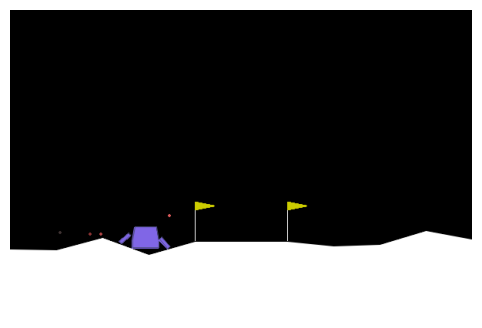

In [2]:
env = gym.make('LunarLander-v3',render_mode='rgb_array')


for episode in range(5):
    current_observation, info = env.reset()

    episode_over = False
    total_reward = 0

    success=0
    while not episode_over:
        action=env.action_space.sample()
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated


        #### Vizalisation ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        #### Vizalisation ####

env.close()


## Train an agent with deep Q-learning

### Definition of the hyperparameters and creation of an agent

In [3]:
n_episodes=100
start_eps=1.0
batch_size=64
update_weights_period=1000


display_train=int(n_episodes/100)

In [ ]:
agent=Agent(
    env=env,

    start_learning_rate=0.002,
    start_factor_lr=1.0,
    end_factor_lr=1.0,
    total_iters_lr=int(n_episodes/2),
    
    start_epsilon=start_eps,
    epsilon_decay = start_eps / (n_episodes/2),
    final_epsilon=0.1,
    gamma=0.99
    )

buffer = ReplayBuffer(capacity=100_000)

### Training loop